Setup and input images

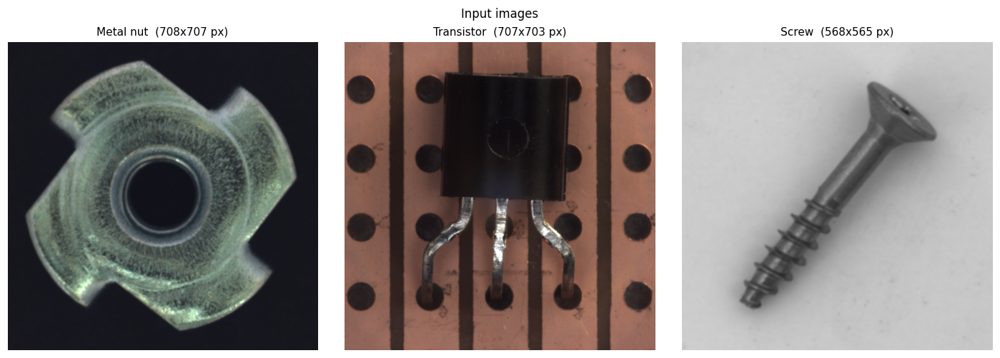

In [1]:
import time
import warnings
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "font.size": 9})

IMAGE_FILES = {
    "Metal nut":  "images/nut.png",
    "Transistor": "images/transistor.png",
    "Screw":      "images/screw.png",
}
NAMES = list(IMAGE_FILES)

bgr, gray = {}, {}
for name, path in IMAGE_FILES.items():
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Could not read {path}. Put the images in an 'images' folder next to the notebook.")
    bgr[name] = img
    gray[name] = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


def show(ax, img, title=""):
    """Show a grayscale or BGR image without axes."""
    if img.ndim == 2:
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")


# Polarity of the "part" in each image, used whenever a binary mask is built:
#   "bright" = part is brighter than its surroundings, "dark" = part is darker
POLARITY = {"Metal nut": "bright", "Transistor": "dark", "Screw": "dark"}

RESULTS = {}   # metrics collected along the way, summarised at the end

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, n in zip(axes, NAMES):
    show(ax, bgr[n], f"{n}  ({gray[n].shape[1]}x{gray[n].shape[0]} px)")
fig.suptitle("Input images", y=1.0)
plt.tight_layout()
plt.show()

Task 1 - Sobel and Canny edge detection

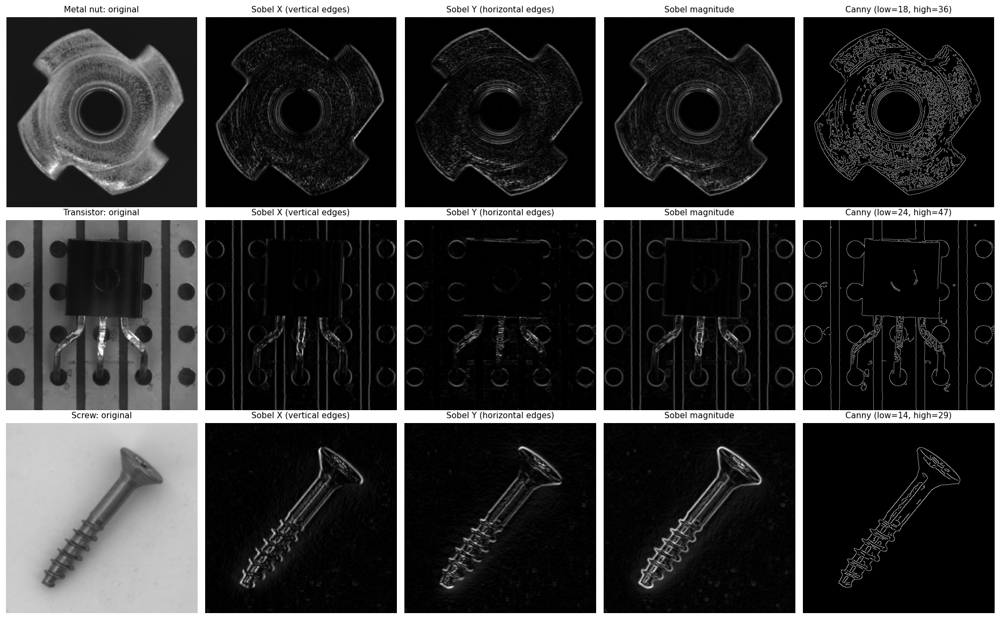

In [18]:
def sobel_edges(g, ksize=3, sigma=1.4):
    """Return Sobel-x, Sobel-y and the normalised gradient magnitude (uint8)."""
    b = cv2.GaussianBlur(g, (0, 0), sigma)
    gx = cv2.Sobel(b, cv2.CV_64F, 1, 0, ksize=ksize)
    gy = cv2.Sobel(b, cv2.CV_64F, 0, 1, ksize=ksize)
    mag = np.hypot(gx, gy)
    to8 = lambda a: cv2.normalize(np.abs(a), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    return to8(gx), to8(gy), to8(mag)


def canny_edges(g, sigma=1.4, hi_scale=1.0):
    """Canny with automatic thresholds (high = Otsu on gradient magnitude x hi_scale, low = high / 2)."""
    b = cv2.GaussianBlur(g, (0, 0), sigma)
    mag = np.hypot(cv2.Sobel(b, cv2.CV_64F, 1, 0), cv2.Sobel(b, cv2.CV_64F, 0, 1))
    otsu_t, _ = cv2.threshold(np.clip(mag, 0, 255).astype(np.uint8), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    hi = otsu_t * hi_scale
    lo = 0.5 * hi
    return cv2.Canny(b, lo, hi, L2gradient=True), (lo, hi)


rows = []
fig, axes = plt.subplots(3, 5, figsize=(17, 10.5))
for r, n in enumerate(NAMES):
    g = gray[n]
    sx, sy, smag = sobel_edges(g)
    canny, (lo, hi) = canny_edges(g)
    # binarise the Sobel magnitude with Otsu so edge pixels can be counted
    _, sobel_bin = cv2.threshold(smag, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    for c, (img, title) in enumerate([
        (g, f"{n}: original"),
        (sx, "Sobel X (vertical edges)"),
        (sy, "Sobel Y (horizontal edges)"),
        (smag, "Sobel magnitude"),
        (canny, f"Canny (low={lo:.0f}, high={hi:.0f})"),
    ]):
        show(axes[r, c], img, title)
    total = g.size
    rows.append({
        "Image": n,
        "Sobel edge px (Otsu on magnitude)": int((sobel_bin > 0).sum()),
        "Sobel edge %": round(100 * (sobel_bin > 0).sum() / total, 2),
        "Canny edge px": int((canny > 0).sum()),
        "Canny edge %": round(100 * (canny > 0).sum() / total, 2),
    })
plt.tight_layout()
plt.show()

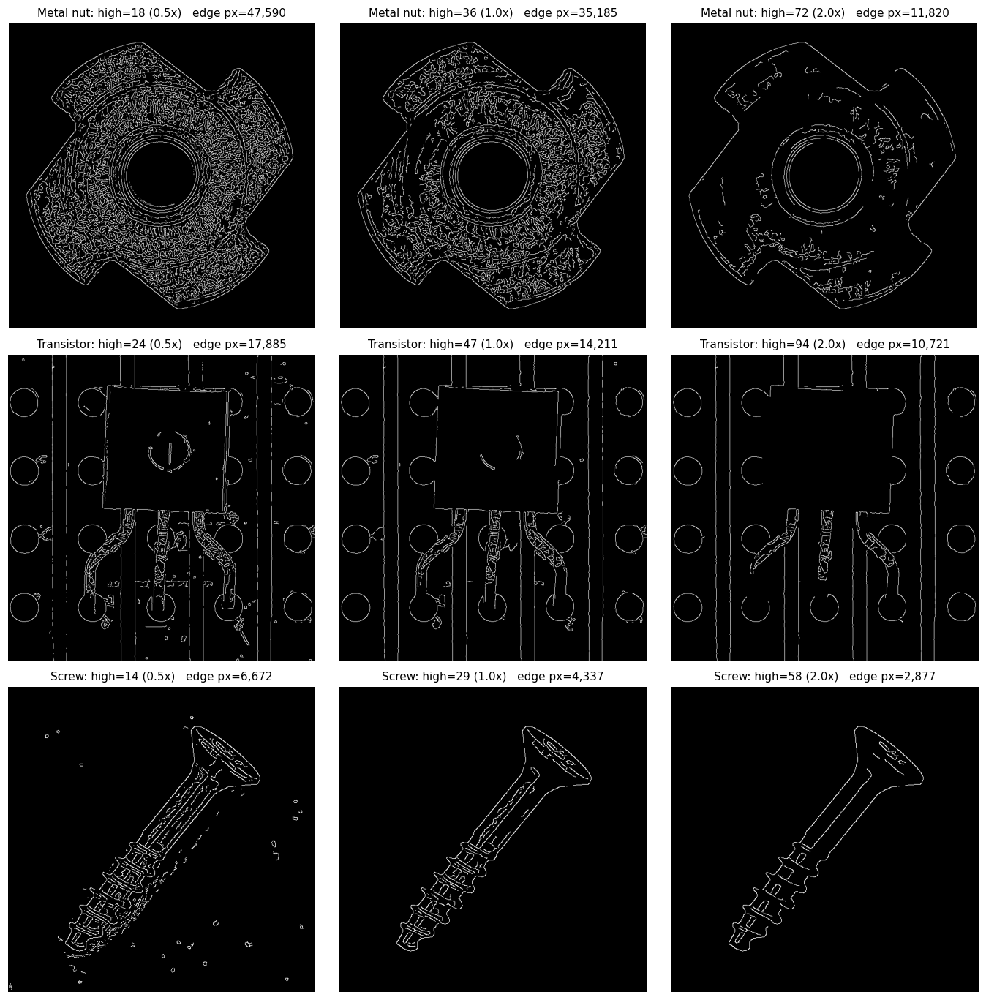

In [3]:
scales = [0.5, 1.0, 2.0]
fig, axes = plt.subplots(3, 3, figsize=(12.5, 12.5))
for r, n in enumerate(NAMES):
    for c, s in enumerate(scales):
        e, (lo, hi) = canny_edges(gray[n], hi_scale=s)
        show(axes[r, c], e, f"{n}: high={hi:.0f} ({s}x)   edge px={int((e > 0).sum()):,}")
plt.tight_layout()
plt.show()

Task 2 - Morphological opening and closing on binary masks

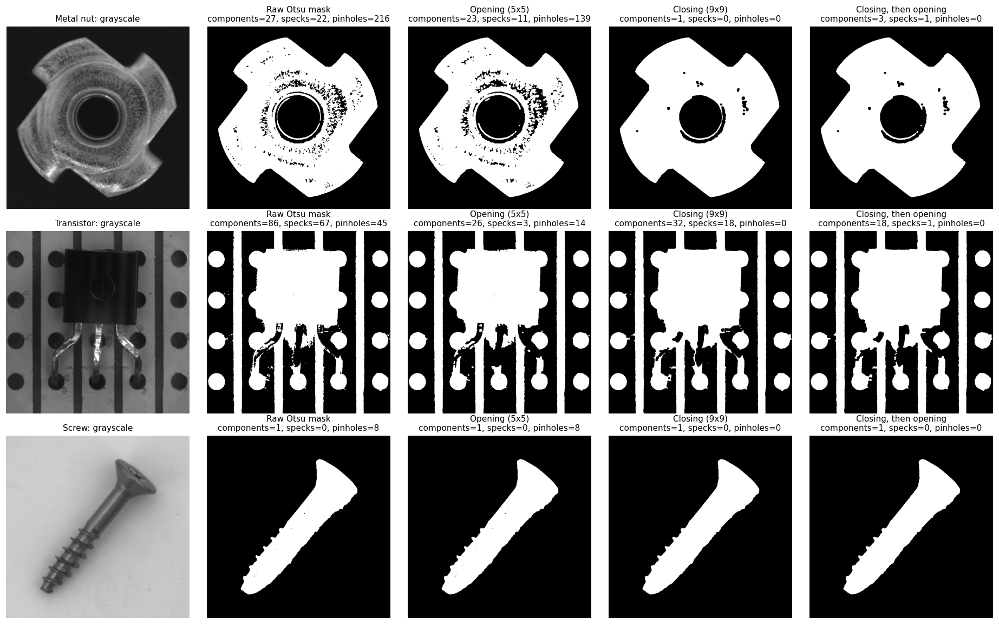

In [19]:
def otsu_mask(g, polarity, blur=3):
    """Otsu mask with the part as white (255)."""
    b = cv2.GaussianBlur(g, (blur, blur), 0) if blur > 1 else g
    flag = cv2.THRESH_BINARY if polarity == "bright" else cv2.THRESH_BINARY_INV
    t, m = cv2.threshold(b, 0, 255, flag + cv2.THRESH_OTSU)
    return m, t


def mask_stats(m, min_area=30):
    """Foreground pixels, number of components, tiny specks and tiny pinholes."""
    n_fg, _, st_fg, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    n_bg, _, st_bg, _ = cv2.connectedComponentsWithStats(255 - m, connectivity=8)
    return {
        "foreground px": int((m > 0).sum()),
        "components": n_fg - 1,
        f"specks (<{min_area}px)": int((st_fg[1:, cv2.CC_STAT_AREA] < min_area).sum()),
        f"pinholes (<{min_area}px)": int((st_bg[1:, cv2.CC_STAT_AREA] < min_area).sum()),
    }


def ellipse(k):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))


OPEN_K, CLOSE_K = 5, 9          # structuring-element sizes (pixels)

RAW, CLEAN = {}, {}
stat_rows = []
fig, axes = plt.subplots(3, 5, figsize=(17, 10.5))
for r, n in enumerate(NAMES):
    raw, t = otsu_mask(gray[n], POLARITY[n], blur=1)       # no blur -> realistic noisy mask
    opened = cv2.morphologyEx(raw, cv2.MORPH_OPEN, ellipse(OPEN_K))
    closed = cv2.morphologyEx(raw, cv2.MORPH_CLOSE, ellipse(CLOSE_K))
    cleaned = cv2.morphologyEx(closed, cv2.MORPH_OPEN, ellipse(OPEN_K))
    RAW[n], CLEAN[n] = raw, cleaned
    stages = [("Raw Otsu mask", raw), (f"Opening ({OPEN_K}x{OPEN_K})", opened),
              (f"Closing ({CLOSE_K}x{CLOSE_K})", closed), ("Closing, then opening", cleaned)]
    show(axes[r, 0], gray[n], f"{n}: grayscale")
    for c, (label, m) in enumerate(stages, start=1):
        s = mask_stats(m)
        show(axes[r, c], m, f"{label}\ncomponents={s['components']}, specks={s['specks (<30px)']}, pinholes={s['pinholes (<30px)']}")
        stat_rows.append({"Image": n, "Stage": label, **s})
plt.tight_layout()
plt.show()


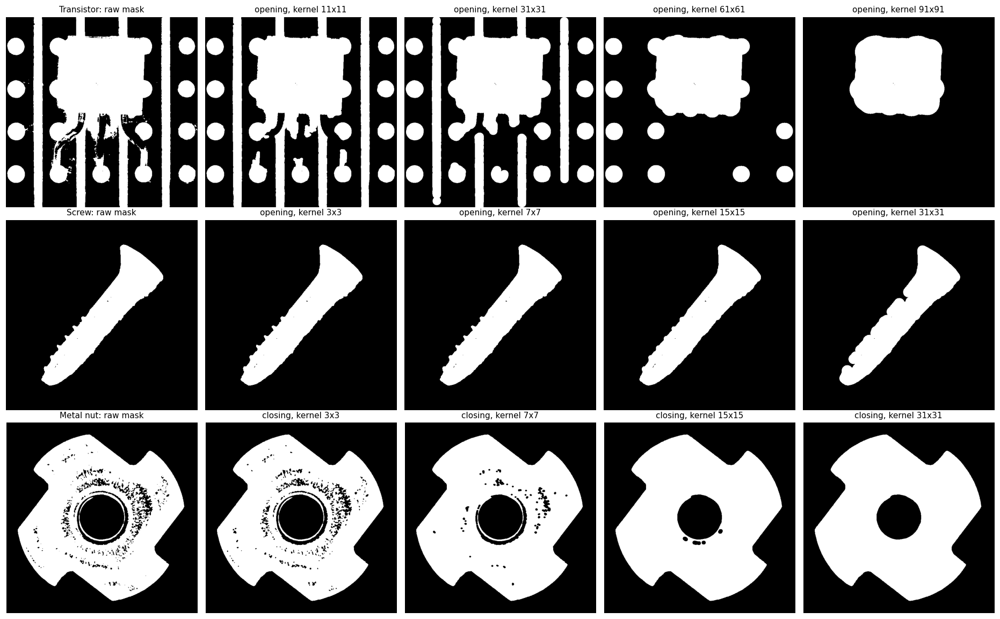

In [5]:
sweeps = [
    ("Transistor", cv2.MORPH_OPEN,  "opening", [11, 31, 61, 91]),
    ("Screw",      cv2.MORPH_OPEN,  "opening", [3, 7, 15, 31]),
    ("Metal nut",  cv2.MORPH_CLOSE, "closing", [3, 7, 15, 31]),
]
fig, axes = plt.subplots(3, 5, figsize=(17, 10.5))
for r, (n, op, lbl, ks) in enumerate(sweeps):
    show(axes[r, 0], RAW[n], f"{n}: raw mask")
    for c, k in enumerate(ks, start=1):
        m = cv2.morphologyEx(RAW[n], op, ellipse(k))
        show(axes[r, c], m, f"{lbl}, kernel {k}x{k}")
plt.tight_layout()
plt.show()

 Task 3 - Defect segmentation with Otsu and adaptive thresholding

3a. Otsu vs adaptive thresholding on the plain images

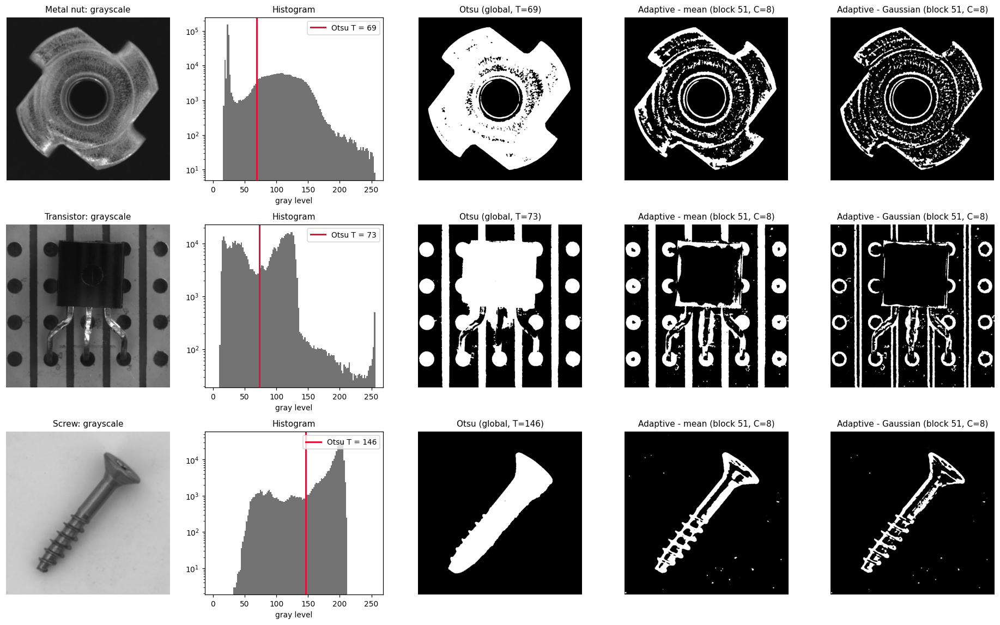

In [6]:
def adaptive_mask(g, polarity, block=51, C=8, method=cv2.ADAPTIVE_THRESH_GAUSSIAN_C, blur=3):
    '''Adaptive threshold, part = white. block must be odd.'''
    b = cv2.GaussianBlur(g, (blur, blur), 0)
    if polarity == "bright":
        return cv2.adaptiveThreshold(b, 255, method, cv2.THRESH_BINARY, block, -C)
    return cv2.adaptiveThreshold(b, 255, method, cv2.THRESH_BINARY_INV, block, C)


fig, axes = plt.subplots(3, 5, figsize=(17, 10.5))
for r, n in enumerate(NAMES):
    g = gray[n]
    otsu, t = otsu_mask(g, POLARITY[n], blur=3)
    a_mean = adaptive_mask(g, POLARITY[n], 51, 8, cv2.ADAPTIVE_THRESH_MEAN_C)
    a_gauss = adaptive_mask(g, POLARITY[n], 51, 8, cv2.ADAPTIVE_THRESH_GAUSSIAN_C)

    show(axes[r, 0], g, f"{n}: grayscale")
    ax = axes[r, 1]
    ax.hist(g.ravel(), bins=128, range=(0, 256), color="0.45")
    ax.axvline(t, color="crimson", lw=2, label=f"Otsu T = {t:.0f}")
    ax.set_title("Histogram"); ax.set_yscale("log"); ax.legend(loc="upper right")
    ax.set_xlabel("gray level")
    show(axes[r, 2], otsu, f"Otsu (global, T={t:.0f})")
    show(axes[r, 3], a_mean, "Adaptive - mean (block 51, C=8)")
    show(axes[r, 4], a_gauss, "Adaptive - Gaussian (block 51, C=8)")
plt.tight_layout()
plt.show()

3b. Uneven illumination

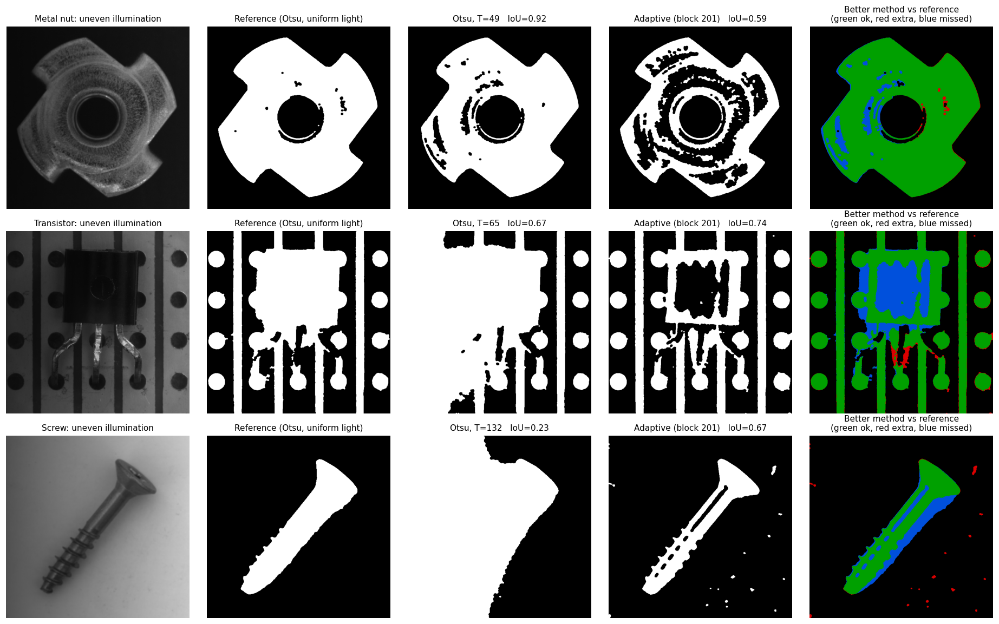

,Otsu IoU (uniform light),Otsu IoU (uneven light),Adaptive IoU (uniform light),Adaptive IoU (uneven light)
Image,,,,
Metal nut,0.995,0.922,0.632,0.589
Transistor,0.992,0.673,0.782,0.744
Screw,0.989,0.227,0.669,0.668


In [7]:
def clean(m, close_k=CLOSE_K, open_k=OPEN_K):
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, ellipse(close_k))
    return cv2.morphologyEx(m, cv2.MORPH_OPEN, ellipse(open_k))


def iou(a, b):
    a, b = a > 0, b > 0
    return (a & b).sum() / max((a | b).sum(), 1)


def add_shading(g, lo=0.4):
    ramp = np.linspace(lo, 1.0, g.shape[1])[None, :]
    return np.clip(g * ramp, 0, 255).astype(np.uint8)


BLOCK, C_ADAPT = 201, 4        # large block: region-like behaviour
rows = []
fig, axes = plt.subplots(3, 5, figsize=(17, 10.5))
for r, n in enumerate(NAMES):
    ref = CLEAN[n]
    shaded = add_shading(gray[n])
    otsu_u, _ = otsu_mask(gray[n], POLARITY[n], blur=3)
    otsu_s, t_s = otsu_mask(shaded, POLARITY[n], blur=3)
    ad_u = adaptive_mask(gray[n], POLARITY[n], BLOCK, C_ADAPT)
    ad_s = adaptive_mask(shaded, POLARITY[n], BLOCK, C_ADAPT)
    scores = {"otsu_u": iou(clean(otsu_u), ref), "otsu_s": iou(clean(otsu_s), ref),
              "ad_u": iou(clean(ad_u), ref), "ad_s": iou(clean(ad_s), ref)}
    show(axes[r, 0], shaded, f"{n}: uneven illumination")
    show(axes[r, 1], ref, "Reference (Otsu, uniform light)")
    show(axes[r, 2], clean(otsu_s), f"Otsu, T={t_s:.0f}   IoU={scores['otsu_s']:.2f}")
    show(axes[r, 3], clean(ad_s), f"Adaptive (block {BLOCK})   IoU={scores['ad_s']:.2f}")
    # difference map: green = agree, red = false part, blue = missed part
    best = clean(otsu_s) if scores["otsu_s"] >= scores["ad_s"] else clean(ad_s)
    ov = np.zeros((*ref.shape, 3), np.uint8)
    ov[(best > 0) & (ref > 0)] = (0, 160, 0)
    ov[(best > 0) & (ref == 0)] = (0, 0, 220)
    ov[(best == 0) & (ref > 0)] = (220, 80, 0)
    show(axes[r, 4], ov, "Better method vs reference\n(green ok, red extra, blue missed)")
    rows.append({"Image": n,
                 "Otsu IoU (uniform light)": round(scores["otsu_u"], 3),
                 "Otsu IoU (uneven light)": round(scores["otsu_s"], 3),
                 "Adaptive IoU (uniform light)": round(scores["ad_u"], 3),
                 "Adaptive IoU (uneven light)": round(scores["ad_s"], 3)})
plt.tight_layout()
plt.show()

illum_table = pd.DataFrame(rows).set_index("Image")
RESULTS["illum"] = illum_table
illum_table

3c. Defect segmentation (scratch and pits) with ground truth

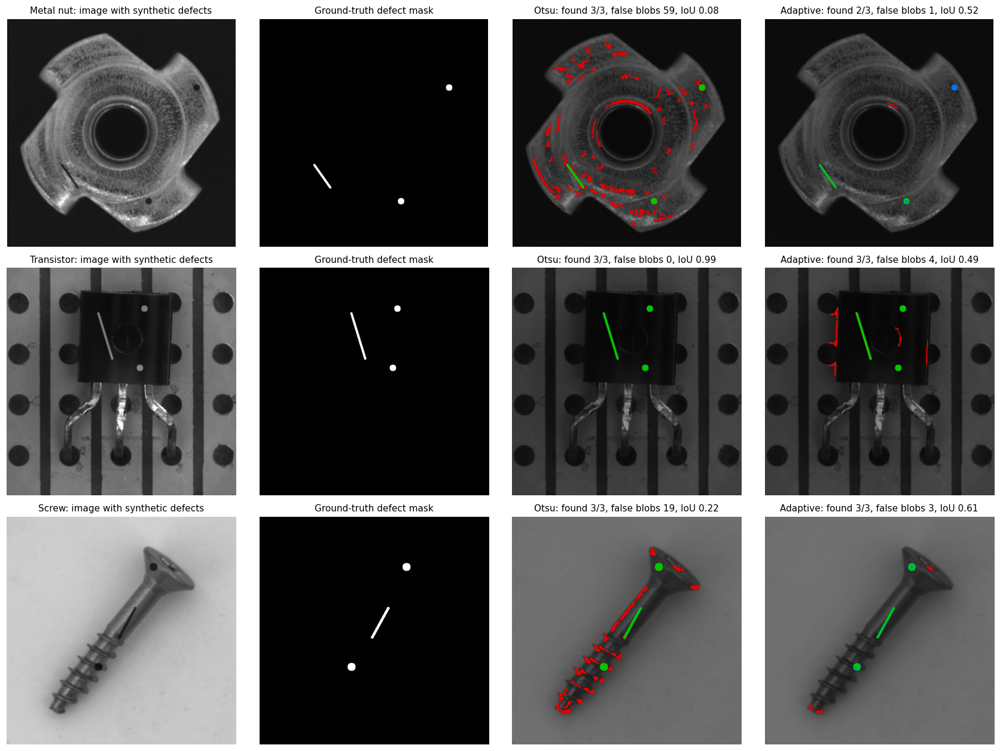

defects found  false blobs  precision  recall   IoU
Image      Method                                                      
Metal nut  Otsu               3/3           59       0.08    1.00  0.08
           Adaptive           2/3            1       0.81    0.59  0.52
Transistor Otsu               3/3            0       1.00    0.99  0.99
           Adaptive           3/3            4       0.49    1.00  0.49
Screw      Otsu               3/3           19       0.22    0.98  0.22
           Adaptive           3/3            3       0.74    0.78  0.61

In [8]:
# --- synthetic defects: positions are fractions of image (x, y); sign -1 = darker, +1 = brighter
DEFECTS = {
    "Metal nut":  dict(scratch=[(0.24, 0.64), (0.31, 0.74)], pits=[(0.83, 0.30), (0.62, 0.80)], sign=-1),
    "Transistor": dict(scratch=[(0.40, 0.20), (0.46, 0.40)], pits=[(0.60, 0.18), (0.58, 0.44)], sign=+1),
    "Screw":      dict(scratch=[(0.56, 0.40), (0.49, 0.53)], pits=[(0.64, 0.22), (0.40, 0.66)], sign=-1),
}
MARGIN = {"Metal nut": 14, "Transistor": 14, "Screw": 6}     # px kept away from the part outline
MIN_AREA = 100


def add_defects(g, name):
    '''Paint a scratch and two pits; return the defective image and the ground-truth mask.'''
    h, w = g.shape
    d = DEFECTS[name]
    alpha = np.zeros((h, w), np.float32)
    pts = np.array([(int(x * w), int(y * h)) for x, y in d["scratch"]], np.int32)
    cv2.polylines(alpha, [pts], False, 1.0, thickness=6, lineType=cv2.LINE_AA)
    for x, y in d["pits"]:
        cv2.circle(alpha, (int(x * w), int(y * h)), 10, 1.0, -1, cv2.LINE_AA)
    gt = (alpha > 0.5).astype(np.uint8) * 255
    alpha = cv2.GaussianBlur(alpha, (0, 0), 1.0)
    out = g * (1 - 0.65 * alpha) if d["sign"] < 0 else g + 110 * alpha
    return np.clip(out, 0, 255).astype(np.uint8), gt


def seg_otsu(g, part, sign):
    bg = cv2.medianBlur(g, 31)
    resid = np.clip((g.astype(np.float32) - bg.astype(np.float32)) * sign, 0, 255).astype(np.uint8)
    t, _ = cv2.threshold(resid[part > 0].reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return ((resid > t) & (part > 0)).astype(np.uint8) * 255, t


def seg_adaptive(g, part, sign, block=41):
    C = 0.25 * float(np.median(g[part > 0]))
    m = adaptive_mask(g, "bright" if sign > 0 else "dark", block=block, C=C)
    return cv2.bitwise_and(m, part), None


def filter_blobs(m, min_area=MIN_AREA):
    n, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    keep = np.zeros_like(m)
    for i in range(1, n):
        if st[i, cv2.CC_STAT_AREA] >= min_area:
            keep[lab == i] = 255
    return keep


def score(pred, gt):
    n_gt, lab_gt, _, _ = cv2.connectedComponentsWithStats(gt, connectivity=8)
    n_pr, lab_pr, _, _ = cv2.connectedComponentsWithStats(pred, connectivity=8)
    found = sum(1 for i in range(1, n_gt) if (pred[lab_gt == i] > 0).any())
    false_blobs = sum(1 for i in range(1, n_pr) if not (gt[lab_pr == i] > 0).any())
    tp = ((pred > 0) & (gt > 0)).sum(); fp = ((pred > 0) & (gt == 0)).sum(); fn = ((pred == 0) & (gt > 0)).sum()
    return {"defects found": f"{found}/{n_gt - 1}", "false blobs": false_blobs,
            "precision": round(tp / max(tp + fp, 1), 2), "recall": round(tp / max(tp + fn, 1), 2),
            "IoU": round(tp / max(tp + fp + fn, 1), 2)}


def overlay(g, pred, gt):
    ov = cv2.cvtColor(g, cv2.COLOR_GRAY2BGR)
    ov = (ov * 0.55).astype(np.uint8)
    ov[(pred > 0) & (gt > 0)] = (0, 200, 0)      # true positive
    ov[(pred > 0) & (gt == 0)] = (0, 0, 230)     # false positive
    ov[(pred == 0) & (gt > 0)] = (230, 120, 0)   # missed
    return ov


rows = []
fig, axes = plt.subplots(3, 4, figsize=(15.5, 11.5))
for r, n in enumerate(NAMES):
    # region where defects are searched: the part (transistor: only its body, found with a large opening)
    base = CLEAN[n] if n != "Transistor" else cv2.morphologyEx(RAW[n], cv2.MORPH_OPEN, ellipse(91))
    part = cv2.erode(base, ellipse(MARGIN[n]))
    gd, gt = add_defects(gray[n], n)
    sign = DEFECTS[n]["sign"]
    show(axes[r, 0], gd, f"{n}: image with synthetic defects")
    show(axes[r, 1], gt, "Ground-truth defect mask")
    for c, (label, fn) in enumerate([("Otsu", seg_otsu), ("Adaptive", seg_adaptive)], start=2):
        m, t = fn(gd, part, sign)
        pred = filter_blobs(cv2.morphologyEx(m, cv2.MORPH_OPEN, ellipse(3)))
        s = score(pred, gt)
        show(axes[r, c], overlay(gd, pred, gt),
             f"{label}: found {s['defects found']}, false blobs {s['false blobs']}, IoU {s['IoU']}")
        rows.append({"Image": n, "Method": label, **s})
plt.tight_layout()
plt.show()

defect_table = pd.DataFrame(rows).set_index(["Image", "Method"])
RESULTS["defects"] = defect_table
defect_table

Task 4 - SIFT and ORB features for part identification and alignment

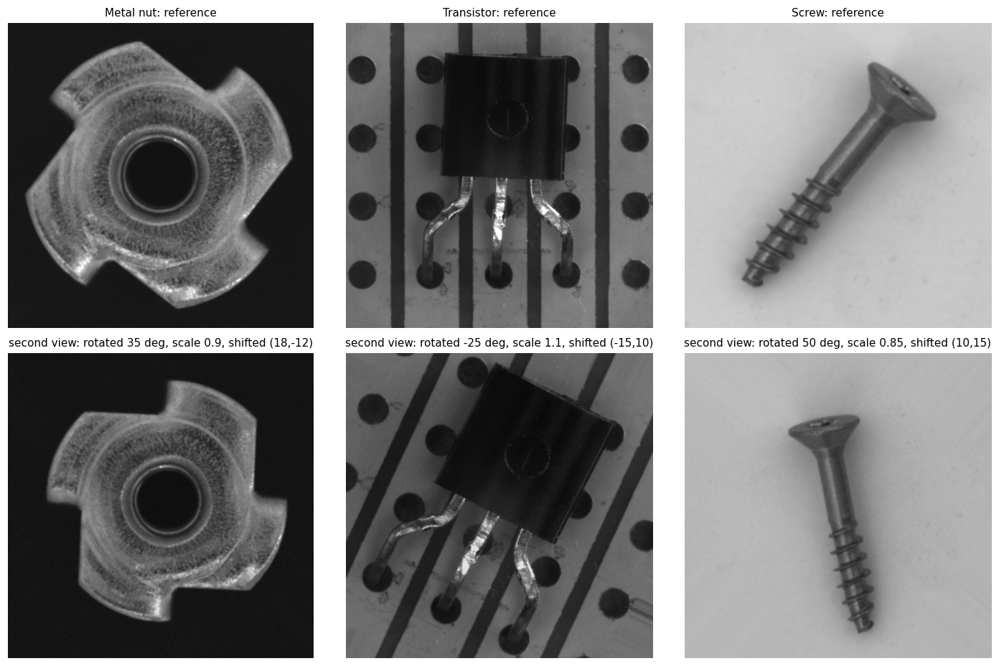

In [9]:
# true transform applied to create the second view of each part: (angle in degrees, scale, shift x, shift y)
VIEW_PARAMS = {"Metal nut": (35, 0.90, 18, -12), "Transistor": (-25, 1.10, -15, 10), "Screw": (50, 0.85, 10, 15)}


def make_second_view(g, angle, scale, dx, dy, gain=0.9, noise=3.0, seed=0):
    h, w = g.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale)
    M[:, 2] += (dx, dy)
    view = cv2.warpAffine(g, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    rng = np.random.default_rng(seed)
    view = np.clip(view * gain + rng.normal(0, noise, view.shape), 0, 255).astype(np.uint8)
    return view, M


VIEW, M_TRUE = {}, {}
for n in NAMES:
    VIEW[n], M_TRUE[n] = make_second_view(gray[n], *VIEW_PARAMS[n])

fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
for c, n in enumerate(NAMES):
    show(axes[0, c], gray[n], f"{n}: reference")
    a, s, dx, dy = VIEW_PARAMS[n]
    show(axes[1, c], VIEW[n], f"second view: rotated {a} deg, scale {s}, shifted ({dx},{dy})")
plt.tight_layout()
plt.show()

4a. Detect, describe and match

In [10]:
def get_detector(method, nfeatures=2000):
    if method == "ORB":
        return cv2.ORB_create(nfeatures=nfeatures, fastThreshold=10), cv2.NORM_HAMMING, 0.80
    return cv2.SIFT_create(nfeatures=nfeatures), cv2.NORM_L2, 0.75


def match_views(g_ref, g_view, method):
    '''Detect + describe + ratio-test match + RANSAC similarity fit. Returns a dict with everything needed.'''
    det, norm, ratio = get_detector(method)
    t0 = time.perf_counter()
    kp1, d1 = det.detectAndCompute(g_ref, None)
    kp2, d2 = det.detectAndCompute(g_view, None)
    out = {"method": method, "kp1": kp1, "kp2": kp2, "good": [], "inliers": [], "M": None}
    if d1 is not None and d2 is not None and len(kp1) > 2 and len(kp2) > 2:
        knn = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2)
        good = [m[0] for m in knn if len(m) == 2 and m[0].distance < ratio * m[1].distance]
        out["good"] = good
        if len(good) >= 3:
            src = np.float32([kp1[m.queryIdx].pt for m in good])
            dst = np.float32([kp2[m.trainIdx].pt for m in good])
            M, mask = cv2.estimateAffinePartial2D(src, dst, method=cv2.RANSAC, ransacReprojThreshold=3.0)
            if M is not None:
                out["M"] = M
                out["inliers"] = [m for m, k in zip(good, mask.ravel()) if k]
    out["time_ms"] = 1000 * (time.perf_counter() - t0)
    return out


def pose(M):
    '''Rotation (deg) and scale of a similarity matrix, in the same convention as cv2.getRotationMatrix2D.'''
    return np.degrees(np.arctan2(-M[1, 0], M[0, 0])), float(np.hypot(M[0, 0], M[1, 0]))


MATCH = {}
rows = []
for n in NAMES:
    a_true, s_true = pose(M_TRUE[n])
    for method in ("ORB", "SIFT"):
        r = match_views(gray[n], VIEW[n], method)
        MATCH[(n, method)] = r
        row = {"Image": n, "Method": method, "keypoints (ref)": len(r["kp1"]), "keypoints (view)": len(r["kp2"]),
               "good matches": len(r["good"]), "RANSAC inliers": len(r["inliers"]),
               "inlier %": round(100 * len(r["inliers"]) / max(len(r["good"]), 1), 1),
               "time (ms)": round(r["time_ms"], 1)}
        if r["M"] is not None:
            a_est, s_est = pose(r["M"])
            row["angle error (deg)"] = round(abs(a_est - a_true), 2)
            row["scale error (%)"] = round(100 * abs(s_est - s_true) / s_true, 2)
        else:
            row["angle error (deg)"] = row["scale error (%)"] = np.nan
        rows.append(row)

feature_table = pd.DataFrame(rows).set_index(["Image", "Method"])
RESULTS["features"] = feature_table
feature_table

keypoints (ref)  keypoints (view)  good matches  \
Image      Method                                                    
Metal nut  ORB                2000              2000          1053   
           SIFT                802               543           423   
Transistor ORB                2000              2000          1009   
           SIFT                538               432           315   
Screw      ORB                 871               956           459   
           SIFT                 79                73            55   

                   RANSAC inliers  inlier %  time (ms)  angle error (deg)  \
Image      Method                                                           
Metal nut  ORB               1002      95.2     4360.6               0.02   
           SIFT               412      97.4      296.9               0.01   
Transistor ORB                889      88.1       45.7               0.00   
           SIFT               281      89.2      215.6               0.01   
Screw      ORB                393      85.6       18.5               0.01   
           SIFT                47      85.5      109.0               0.02   

                   scale error (%)  
Image      Method                   
Metal nut  ORB                0.01  
           SIFT               0.01  
Transistor ORB                0.06  
           SIFT               0.00  
Screw      ORB                0.06  
           SIFT               0.03

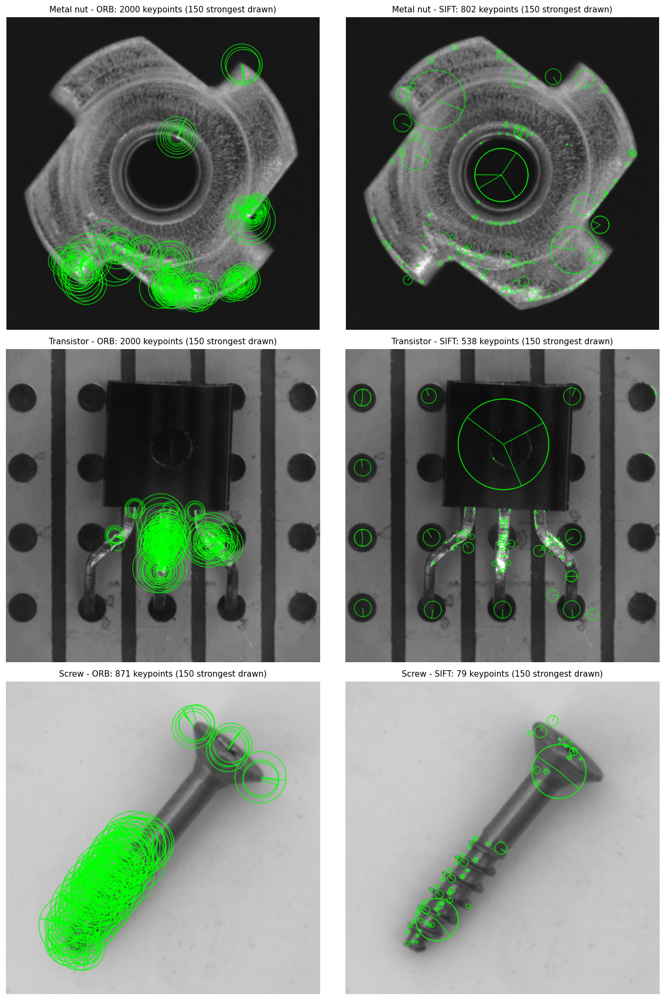

In [12]:
fig, axes = plt.subplots(3, 2, figsize=(12, 17))
for r, n in enumerate(NAMES):
    for c, method in enumerate(("ORB", "SIFT")):
        kps = sorted(MATCH[(n, method)]["kp1"], key=lambda k: -k.response)[:150]
        img = cv2.drawKeypoints(cv2.cvtColor(gray[n], cv2.COLOR_GRAY2BGR), kps, None, color=(0, 255, 0),
                                flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
        show(axes[r, c], img, f"{n} - {method}: {len(MATCH[(n, method)]['kp1'])} keypoints (150 strongest drawn)")
plt.tight_layout()
plt.show()

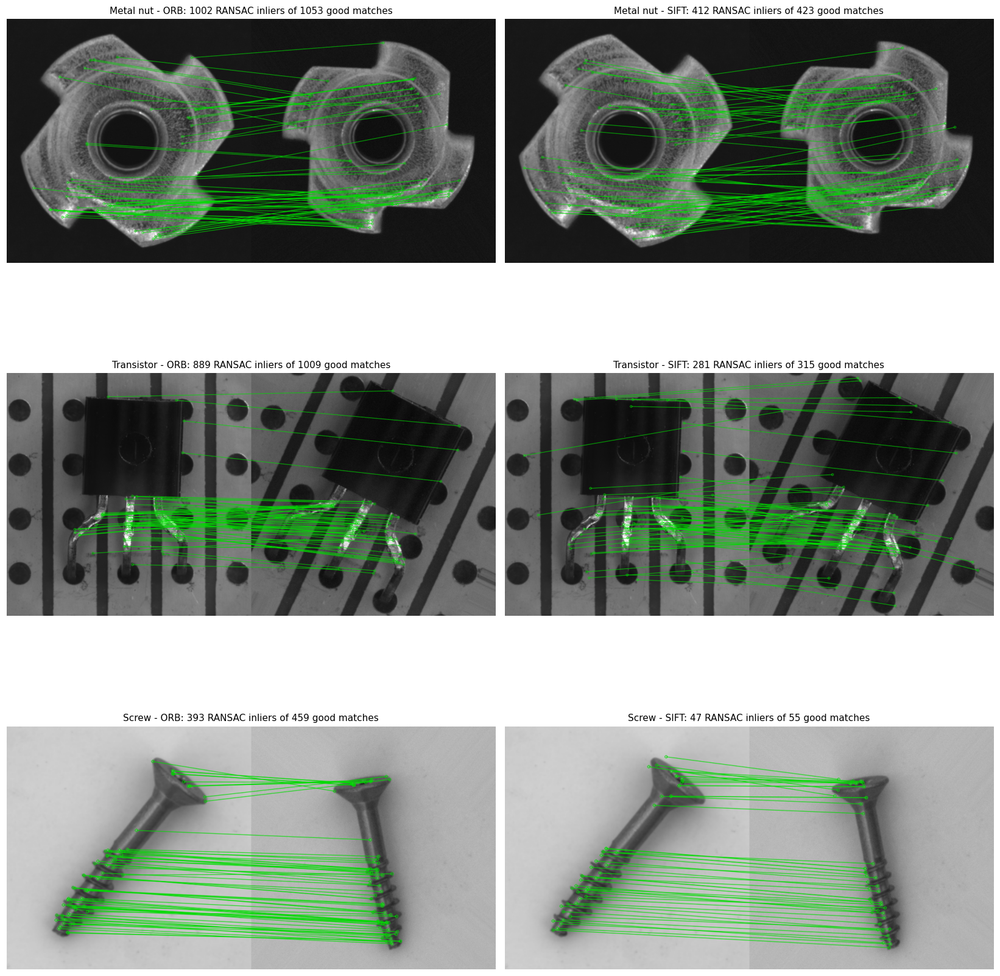

In [13]:
fig, axes = plt.subplots(3, 2, figsize=(15, 17))
for r, n in enumerate(NAMES):
    for c, method in enumerate(("ORB", "SIFT")):
        m = MATCH[(n, method)]
        shown = m["inliers"][:: max(1, len(m["inliers"]) // 60)]          
        img = cv2.drawMatches(cv2.cvtColor(gray[n], cv2.COLOR_GRAY2BGR), m["kp1"],
                              cv2.cvtColor(VIEW[n], cv2.COLOR_GRAY2BGR), m["kp2"], shown, None,
                              matchColor=(0, 220, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
        show(axes[r, c], img, f"{n} - {method}: {len(m['inliers'])} RANSAC inliers of {len(m['good'])} good matches")
plt.tight_layout()
plt.show()

4b. Alignment

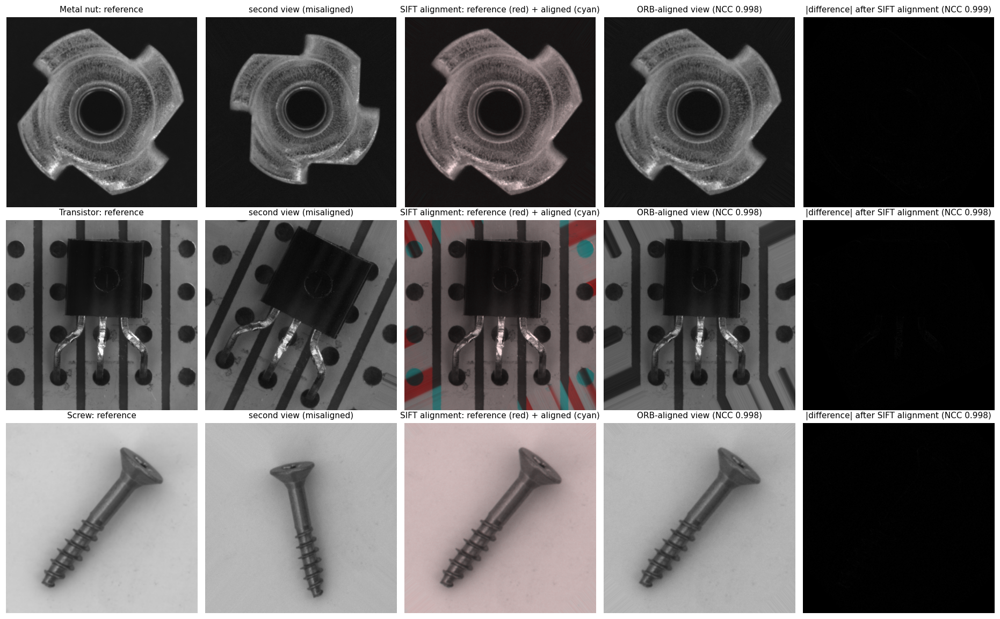

NCC before alignment  NCC after alignment
Image      Method                                           
Metal nut  ORB                    0.460                0.998
           SIFT                   0.460                0.999
Transistor ORB                    0.353                0.998
           SIFT                   0.353                0.998
Screw      ORB                    0.259                0.998
           SIFT                   0.258                0.998

In [14]:
def align(view, M, shape):
    return cv2.warpAffine(view, M, (shape[1], shape[0]), flags=cv2.INTER_LINEAR + cv2.WARP_INVERSE_MAP,
                          borderMode=cv2.BORDER_REPLICATE)


def valid_region(M, shape):
    ones = np.full(shape, 255, np.uint8)
    v = cv2.warpAffine(ones, M, (shape[1], shape[0]), flags=cv2.WARP_INVERSE_MAP, borderValue=0)
    return cv2.erode(v, ellipse(15)) > 0


def ncc(a, b, valid):
    # zero-mean normalised cross-correlation (1.0 = identical up to brightness/contrast), insensitive to the brightness gain
    a, b = a[valid].astype(float), b[valid].astype(float)
    a, b = a - a.mean(), b - b.mean()
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum()))


rows = []
fig, axes = plt.subplots(3, 5, figsize=(17, 10.5))
for r, n in enumerate(NAMES):
    ref, view = gray[n], VIEW[n]
    show(axes[r, 0], ref, f"{n}: reference")
    show(axes[r, 1], view, "second view (misaligned)")
    for method, col in (("ORB", 2), ("SIFT", 3)):
        m = MATCH[(n, method)]
        aligned = align(view, m["M"], ref.shape)
        valid = valid_region(m["M"], ref.shape)
        ncc_before = ncc(view, ref, valid)
        ncc_after = ncc(aligned, ref, valid)
        rows.append({"Image": n, "Method": method, "NCC before alignment": round(ncc_before, 3),
                     "NCC after alignment": round(ncc_after, 3)})
        if method == "SIFT":
            overlay_img = cv2.merge([aligned, aligned, ref])                 # B,G = aligned (cyan), R = reference
            show(axes[r, 2], overlay_img, "SIFT alignment: reference (red) + aligned (cyan)")
            # difference after matching brightness/contrast, shown only where the aligned view has real pixels
            a_norm = (aligned.astype(float) - aligned[valid].mean()) / aligned[valid].std() * ref[valid].std() + ref[valid].mean()
            diff = np.where(valid, np.abs(a_norm - ref), 0).clip(0, 255).astype(np.uint8)
            show(axes[r, 4], diff, f"|difference| after SIFT alignment (NCC {ncc_after:.3f})")
        else:
            show(axes[r, 3], aligned, f"ORB-aligned view (NCC {ncc_after:.3f})")
plt.tight_layout()
plt.show()

align_table = pd.DataFrame(rows).set_index(["Image", "Method"])
RESULTS["align"] = align_table
align_table

4c. Part identification

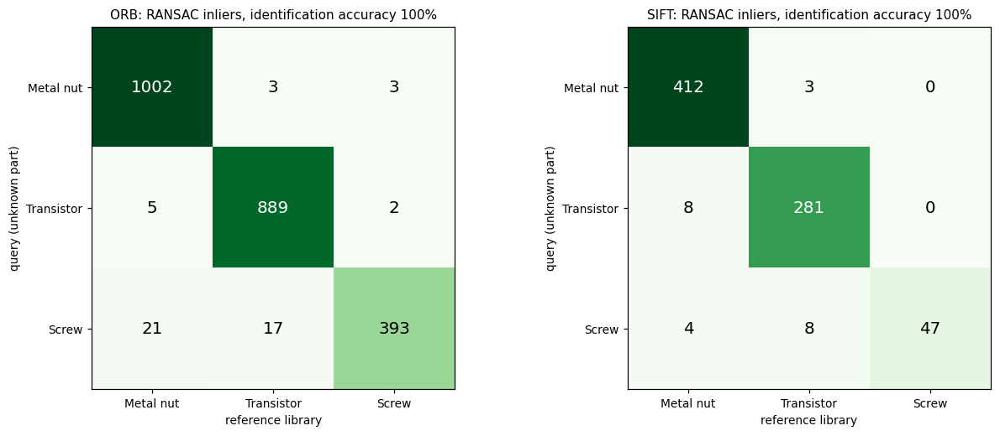

Predicted parts (rows = true part):
  ORB:  {'Metal nut': 'Metal nut', 'Transistor': 'Transistor', 'Screw': 'Screw'}
  SIFT:  {'Metal nut': 'Metal nut', 'Transistor': 'Transistor', 'Screw': 'Screw'}


In [15]:
MIN_INLIERS = 30
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ident = {}
for ax, method in zip(axes, ("ORB", "SIFT")):
    score_m = np.zeros((3, 3), int)
    for qi, q in enumerate(NAMES):                       # query = second view of part q
        for ri, ref_name in enumerate(NAMES):           # reference library entry
            score_m[qi, ri] = len(match_views(gray[ref_name], VIEW[q], method)["inliers"])
    pred = [NAMES[row.argmax()] if row.max() >= MIN_INLIERS else "unknown" for row in score_m]
    acc = np.mean([p == q for p, q in zip(pred, NAMES)])
    ident[method] = (score_m, pred, acc)
    ax.imshow(score_m, cmap="Greens", vmin=0, vmax=max(score_m.max(), 1))
    ax.set_xticks(range(3), NAMES); ax.set_yticks(range(3), NAMES)
    ax.set_xlabel("reference library"); ax.set_ylabel("query (unknown part)")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, str(score_m[i, j]), ha="center", va="center",
                    color="white" if score_m[i, j] > 0.6 * score_m.max() else "black", fontsize=13)
    ax.set_title(f"{method}: RANSAC inliers, identification accuracy {acc:.0%}")
plt.tight_layout()
plt.show()
RESULTS["ident"] = ident
print("Predicted parts (rows = true part):")
for method in ("ORB", "SIFT"):
    print(f"  {method}: ", dict(zip(NAMES, ident[method][1])))